__IMPORTING THINGS__

In [2]:
import os
print(os.getcwd())          # the folder your notebook is running in
print(os.listdir("."))      # you should see 'train', 'val', 'test' in this list
print(os.listdir("train")[:10])   # first 10 file names, e.g. cat.01.jpg, dog.01.jpg

c:\Users\ACER\Desktop\First_Sem\AIAPP\Trying_to_train_a_model
['.venv', '.vscode', 'dogs_vs_cats_subset', 'dog_cat_model.keras', 'main.py', 'modeltest_and_train.ipynb', 'proto1', 'test', 'train', 'val', 'venv310']
['cat.0.jpg', 'cat.1.jpg', 'cat.10.jpg', 'cat.100.jpg', 'cat.101.jpg', 'cat.102.jpg', 'cat.103.jpg', 'cat.104.jpg', 'cat.105.jpg', 'cat.106.jpg']


In [3]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers


In [4]:
print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)

TensorFlow: 2.22.0-rc0
Keras: 3.15.1


In [5]:
IMG_SIZE = (128, 128)
BASE_DIR = "."

train_dir = os.path.join(BASE_DIR, "train")
val_dir   = os.path.join(BASE_DIR, "val")
test_dir  = os.path.join(BASE_DIR, "test")

In [6]:
for name, folder in [("train", train_dir), ("val", val_dir), ("test", test_dir)]:
    files = os.listdir(folder)
    cats = sum(f.lower().startswith("cat") for f in files)
    dogs = sum(f.lower().startswith("dog") for f in files)
    print(f"{name}: {cats} cats, {dogs} dogs")

train: 500 cats, 500 dogs
val: 100 cats, 100 dogs
test: 0 cats, 0 dogs


In [7]:
files = os.listdir(test_dir)
print("Number of items:", len(files))
print(files[:15])

Number of items: 100
['1.jpg', '10.jpg', '100.jpg', '11.jpg', '12.jpg', '13.jpg', '14.jpg', '15.jpg', '16.jpg', '17.jpg', '18.jpg', '19.jpg', '2.jpg', '20.jpg', '21.jpg']


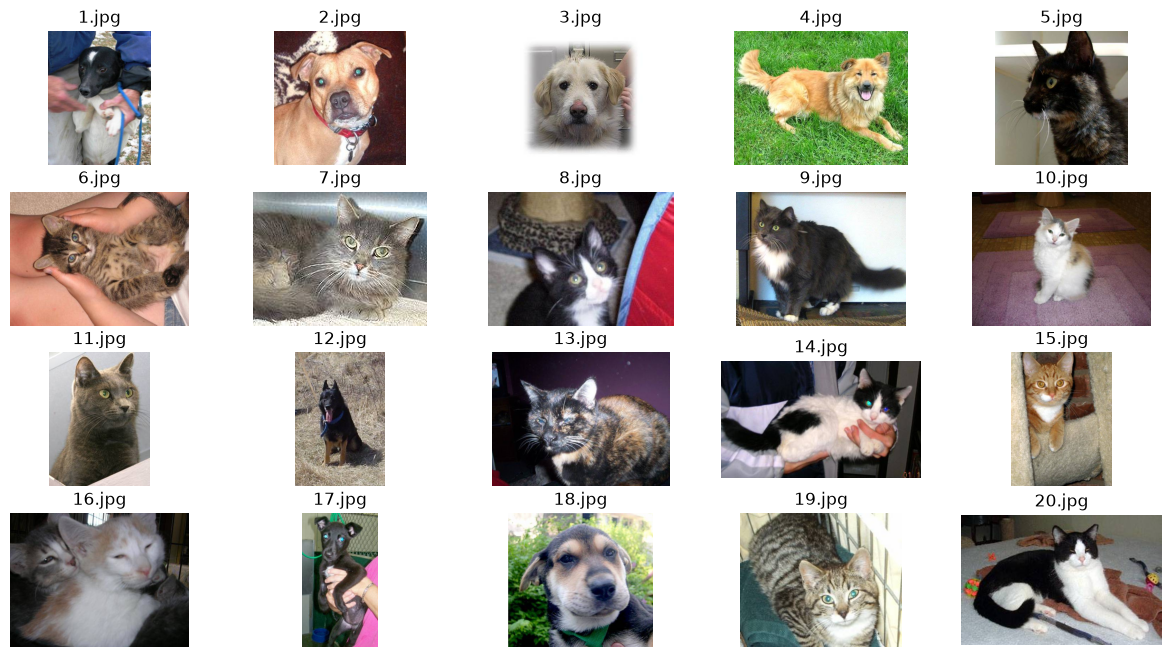

In [8]:
test_files = sorted(os.listdir(test_dir), key=lambda f: int(f.split(".")[0]))

def show_batch(start, n=20):
    plt.figure(figsize=(15, 8))
    for i, f in enumerate(test_files[start:start+n]):
        plt.subplot(4, 5, i + 1)
        plt.imshow(Image.open(os.path.join(test_dir, f)).convert("RGB"))
        plt.title(f)
        plt.axis("off")
    plt.show()

show_batch(0)    # then 20, 40, 60, 80

In [9]:
dog_files = ["1.jpg", "2.jpg", "3.jpg", "4.jpg", "12.jpg", "17.jpg", "18.jpg", "21.jpg", "23.jpg", "24.jpg", "26.jpg", "27.jpg", "30.jpg", "31.jpg", "32.jpg", "33.jpg", "39.jpg", "41.jpg", "42.jpg", "43.jpg", "44.jpg", "46.jpg", "48.jpg", "49.jpg", "56.jpg", "57.jpg", "59.jpg", "62.jpg", "65.jpg", "66.jpg", "67.jpg", "69.jpg", "70.jpg", "71.jpg", "72.jpg", "73.jpg", "74.jpg", "76.jpg", "77.jpg", "78.jpg", "79.jpg", "83.jpg", "85.jpg", "86.jpg", "87.jpg", "88.jpg", "94.jpg", "95.jpg", "97.jpg", "98.jpg"]   # replace with the numbers you saw as dogs
# everything not in this list is treated as a cat

In [10]:
def load_split(folder, dog_files=None):
    images = []
    labels = []

    for filename in sorted(os.listdir(folder)):
        name = filename.lower()

        # skip anything that isn't an image (e.g. .ipynb_checkpoints)
        if not name.endswith((".jpg", ".jpeg", ".png")):
            continue

        # decide the label
        if dog_files is not None:
            # test split: the label comes from YOUR list
            label = 1 if filename in dog_files else 0
        elif name.startswith("cat"):
            label = 0
        elif name.startswith("dog"):
            label = 1
        else:
            continue

        path = os.path.join(folder, filename)
        img = Image.open(path).convert("RGB").resize(IMG_SIZE)
        arr = np.array(img, dtype="float32") / 255.0

        images.append(arr)
        labels.append(label)

    return np.array(images), np.array(labels)

In [11]:
X_train, y_train = load_split(train_dir)
X_val,   y_val   = load_split(val_dir)
X_test,  y_test  = load_split(test_dir, dog_files=dog_files)

print("Train:", X_train.shape, y_train.shape, "dogs:", y_train.sum())
print("Val:  ", X_val.shape, y_val.shape, "dogs:", y_val.sum())
print("Test: ", X_test.shape, y_test.shape, "dogs:", y_test.sum())

Train: (1000, 128, 128, 3) (1000,) dogs: 500
Val:   (200, 128, 128, 3) (200,) dogs: 100
Test:  (100, 128, 128, 3) (100,) dogs: 50


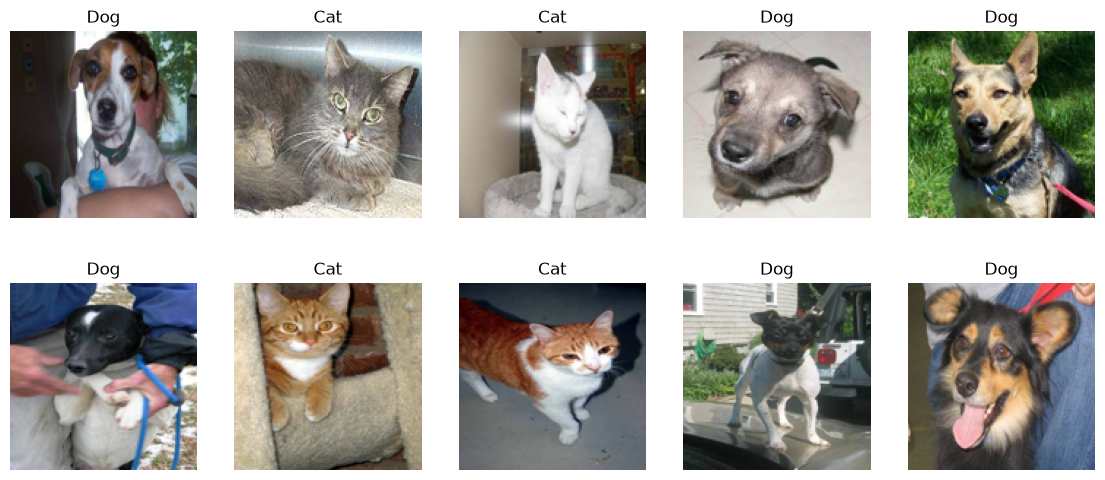

In [12]:
plt.figure(figsize=(14, 6))
for i, idx in enumerate(np.random.choice(len(X_test), 10, replace=False)):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[idx])
    plt.title("Dog" if y_test[idx] == 1 else "Cat")
    plt.axis("off")
plt.show()

In [13]:
model = keras.Sequential([
    layers.Input(shape=(128, 128, 3)),

    # data augmentation (only active during training)
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(1, activation="sigmoid"),
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 128, 128, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,304,769 (12.61 MB)

 Trainable params: 3,304,769 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [14]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

In [15]:
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=32,
)

Epoch 1/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 8s 167ms/step - accuracy: 0.4990 - loss: 0.7022 - val_accuracy: 0.4950 - val_loss: 0.6909
Epoch 2/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 5s 150ms/step - accuracy: 0.5830 - loss: 0.6821 - val_accuracy: 0.6950 - val_loss: 0.6541
Epoch 3/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 5s 146ms/step - accuracy: 0.6300 - loss: 0.6443 - val_accuracy: 0.5650 - val_loss: 0.6452
Epoch 4/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 5s 146ms/step - accuracy: 0.6340 - loss: 0.6478 - val_accuracy: 0.6950 - val_loss: 0.6249
Epoch 5/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 6s 159ms/step - accuracy: 0.6880 - loss: 0.6085 - val_accuracy: 0.6900 - val_loss: 0.6804
Epoch 6/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 5s 162ms/step - accuracy: 0.6450 - loss: 0.6156 - val_accuracy: 0.6400 - val_loss: 0.6220
Epoch 7/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 5s 151ms/step - accuracy: 0.6870 - loss: 0.5863 - val_accuracy: 0.7400 - val_loss: 0.5793
Epoch 8/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 5s 155ms/step - accuracy: 0.7110 - loss: 0.5691 - val_accuracy: 0.

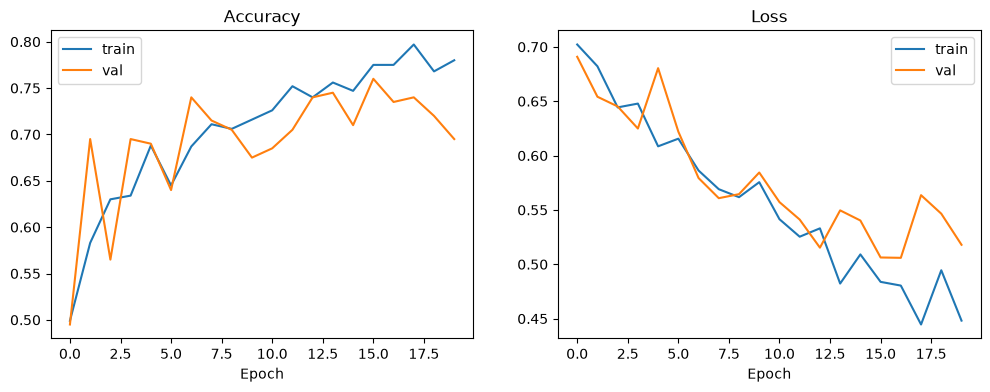

In [16]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="train")
plt.plot(history.history["val_accuracy"], label="val")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="val")
plt.title("Loss")
plt.xlabel("Epoch")
plt.legend()

plt.show()

In [17]:
test_loss, test_acc = model.evaluate(X_test, y_test)
print(f"Test accuracy: {test_acc:.2%}")

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.7700 - loss: 0.5198
Test accuracy: 77.00%


In [18]:
history2 = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=32,
)

Epoch 1/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 4s 136ms/step - accuracy: 0.7780 - loss: 0.4773 - val_accuracy: 0.7350 - val_loss: 0.5492
Epoch 2/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 4s 125ms/step - accuracy: 0.7900 - loss: 0.4566 - val_accuracy: 0.7750 - val_loss: 0.5026
Epoch 3/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 4s 127ms/step - accuracy: 0.8090 - loss: 0.4090 - val_accuracy: 0.7350 - val_loss: 0.5260
Epoch 4/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 4s 131ms/step - accuracy: 0.8160 - loss: 0.4053 - val_accuracy: 0.7400 - val_loss: 0.5396
Epoch 5/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 4s 133ms/step - accuracy: 0.8300 - loss: 0.3853 - val_accuracy: 0.7400 - val_loss: 0.4961
Epoch 6/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 4s 138ms/step - accuracy: 0.8360 - loss: 0.3875 - val_accuracy: 0.7650 - val_loss: 0.4968
Epoch 7/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 5s 153ms/step - accuracy: 0.8160 - loss: 0.4015 - val_accuracy: 0.7650 - val_loss: 0.4901
Epoch 8/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 5s 148ms/step - accuracy: 0.8120 - loss: 0.3985 - val_accuracy: 0.

In [19]:
history2 = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=32,
)

Epoch 1/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 4s 133ms/step - accuracy: 0.8660 - loss: 0.3045 - val_accuracy: 0.7850 - val_loss: 0.4894
Epoch 2/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 4s 131ms/step - accuracy: 0.8950 - loss: 0.2564 - val_accuracy: 0.7700 - val_loss: 0.7656
Epoch 3/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 4s 130ms/step - accuracy: 0.8680 - loss: 0.2823 - val_accuracy: 0.7550 - val_loss: 0.5512
Epoch 4/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 4s 130ms/step - accuracy: 0.8670 - loss: 0.2978 - val_accuracy: 0.7550 - val_loss: 0.6115
Epoch 5/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 4s 129ms/step - accuracy: 0.9130 - loss: 0.2296 - val_accuracy: 0.7700 - val_loss: 0.6225
Epoch 6/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 4s 127ms/step - accuracy: 0.9110 - loss: 0.2246 - val_accuracy: 0.7800 - val_loss: 0.5207
Epoch 7/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 4s 128ms/step - accuracy: 0.8910 - loss: 0.2699 - val_accuracy: 0.7700 - val_loss: 0.5867
Epoch 8/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 4s 127ms/step - accuracy: 0.9020 - loss: 0.2268 - val_accuracy: 0.

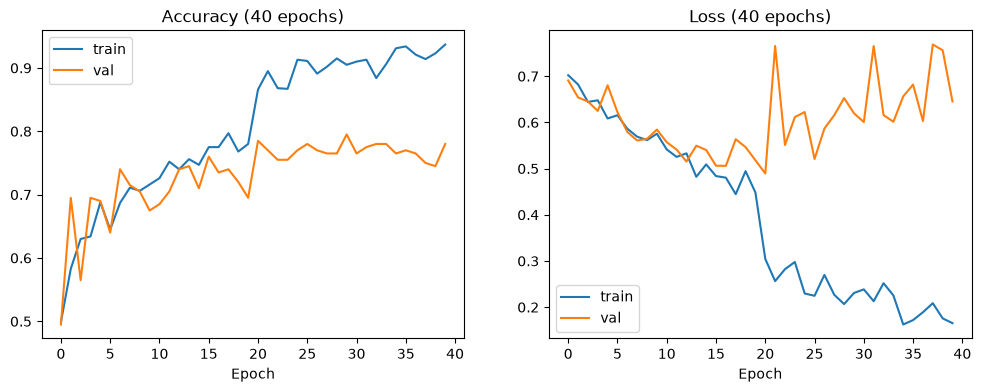

In [20]:
acc      = history.history["accuracy"]     + history2.history["accuracy"]
val_acc  = history.history["val_accuracy"] + history2.history["val_accuracy"]
loss     = history.history["loss"]         + history2.history["loss"]
val_loss = history.history["val_loss"]     + history2.history["val_loss"]

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(acc, label="train")
plt.plot(val_acc, label="val")
plt.title("Accuracy (40 epochs)")
plt.xlabel("Epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(loss, label="train")
plt.plot(val_loss, label="val")
plt.title("Loss (40 epochs)")
plt.xlabel("Epoch")
plt.legend()

plt.show()

In [21]:
test_loss, test_acc = model.evaluate(X_test, y_test)
print(f"Test accuracy: {test_acc:.2%}")

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.7900 - loss: 0.7384
Test accuracy: 79.00%


In [22]:
from sklearn.metrics import confusion_matrix, classification_report

probs = model.predict(X_test).ravel()
preds = (probs > 0.5).astype(int)

print(confusion_matrix(y_test, preds))
print(classification_report(y_test, preds, target_names=["Cat", "Dog"]))

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
[[34 16]
 [ 5 45]]
              precision    recall  f1-score   support

         Cat       0.87      0.68      0.76        50
         Dog       0.74      0.90      0.81        50

    accuracy                           0.79       100
   macro avg       0.80      0.79      0.79       100
weighted avg       0.80      0.79      0.79       100



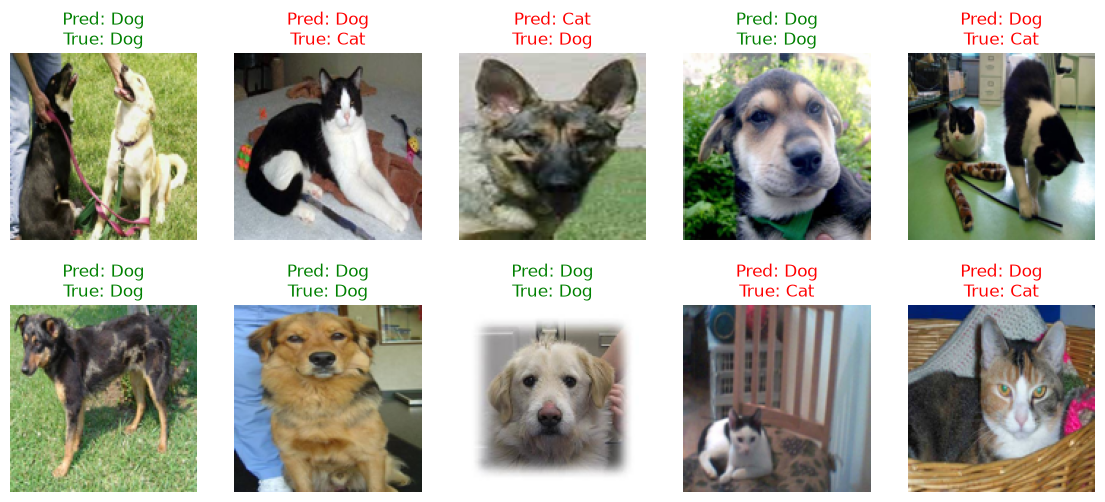

In [26]:
plt.figure(figsize=(14, 6))
for i, idx in enumerate(np.random.choice(len(X_test), 10, replace=False)):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[idx])
    guess = "Dog" if preds[idx] == 1 else "Cat"
    truth = "Dog" if y_test[idx] == 1 else "Cat"
    plt.title(f"Pred: {guess}\nTrue: {truth}", color="green" if guess == truth else "red")
    plt.axis("off")
plt.show()

In [24]:
model.save("dog_cat_model.keras")

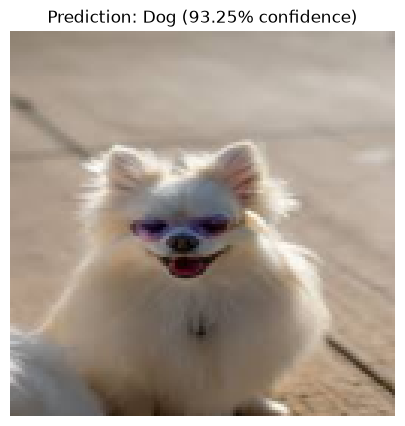

Prediction: Dog
Confidence: 93.25%


In [29]:

from tkinter import Tk, filedialog
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

def predict_image(img):
    # Prepare the image in the same way as training images
    img = img.convert("RGB")
    img = img.resize((128, 128))

    img_array = np.array(img, dtype="float32") / 255.0
    img_array = np.expand_dims(img_array, axis=0)

    # Ask the trained model for a prediction
    probability = model.predict(img_array, verbose=0)[0][0]

    if probability >= 0.5:
        label = "Dog"
        confidence = probability * 100
    else:
        label = "Cat"
        confidence = (1 - probability) * 100

    # Display the image and prediction
    plt.figure(figsize=(5, 5))
    plt.imshow(img)
    plt.title(f"Prediction: {label} ({confidence:.2f}% confidence)")
    plt.axis("off")
    plt.show()

    print("Prediction:", label)
    print(f"Confidence: {confidence:.2f}%")

def upload_photo():
    root = Tk()
    root.withdraw()
    root.attributes("-topmost", True)

    file_path = filedialog.askopenfilename(
        title="Choose a cat or dog photo",
        filetypes=[
            ("Image files", "*.jpg *.jpeg *.png *.bmp *.webp")
        ]
    )

    root.destroy()

    if file_path:
        img = Image.open(file_path)
        predict_image(img)
    else:
        print("No image selected.")

upload_photo()
